In [ ]:
# CREATE ERROR CSV FILES

from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nights_folder = Path("E:/images")

nights = [
    night
    for night in nights_folder.iterdir()
    if "test" not in night.stem and "temp" not in night.stem and "TEST" not in night.stem
]
for night in nights[108:]:
    print(night)
    columns_headers = {
        "FILENAME": [],
        "DATE-OBS": [],
        "NCYCLES": [],
        "CYCLIND": [],
        "NSEQ": [],
        "SEQINDEX": [],
        "NFRAMES": [],
        "FRAMEIND": [],
        "EXPTIME": [],
        "WPPOS": [],
        "WPANG": [],
        "ERROR": [],
    }
    images = list(night.glob("*.fits"))

    for image in images:
        hdr = fits.getheader(image)
        if hdr["INSTMODE"] != "POLAR":
            continue
        if hdr["OBSTYPE"] != "OBJECT":
            continue
        if hdr["WPANG"] == "":
            continue
        if hdr["WPPOS"] == "":
            continue
        for key in columns_headers:
            if key == "ERROR":
                expected_ang = 22.5 * (hdr["WPPOS"] - 1)
                error = expected_ang - hdr["WPANG"]
                columns_headers["ERROR"].append(error)
            else:
                columns_headers[key].append(hdr[key])

    df = pd.DataFrame.from_dict(columns_headers)
    df = df[-300 < df["ERROR"]]
    csv_file = Path.cwd() / "_csv" / f"{night.stem}.csv"
    df.to_csv(csv_file, index=False)

In [ ]:
# FILTER 1 FRAME

import pandas as pd
from pathlib import Path


csv_folder = Path.cwd() / "_csv" / "raw"
for night in csv_folder.iterdir():
    df = pd.read_csv(night)
    df = df[df["FRAMEIND"] == 1]
    csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night.stem}.csv"
    df.to_csv(csv_file, index=False)


In [ ]:
# FILTER CSVs

import pandas as pd
from pathlib import Path

headers = ["Date", "N. images", "Cycles"]
report = {k: [] for k in headers}

csv_folder = Path.cwd() / "_csv" / "1_frame"
for night in csv_folder.iterdir():
    report["Date"].append(night.stem)
    df = pd.read_csv(night)
    report["N. images"].append(df.shape[0])
    report["Cycles"].append(df["CYCLIND"].max())

report = pd.DataFrame.from_dict(report)
report = report.sort_values("Cycles", ascending=False)
report_file = Path.cwd() / "report.csv"
report.to_csv(report_file, index=False)
print(report.head(16))
print(report["Date"].head(16).values)


In [ ]:
# CREATE REPORT

import pandas as pd
from pathlib import Path

headers = ["Date", "N. images", "Cycles"]
report = {k: [] for k in headers}

csv_folder = Path.cwd() / "_csv" / "1_frame"
obs_nights = [
    "20260727",
    "20260728",
    "20260822",
    "20260731",
    "20260719",
    "20260713",
    "20260714",
    "20260823",
    "20260604",
    "20260816",
    "20260819",
    "20260809",
    "20260803",
    "20260715",
    "20260805",
    "20260702",
    "20260607",
    "20260606",
    "20260605",
    "20260815",
]
for night in obs_nights:
    report["Date"].append(night)
    df = pd.read_csv(csv_folder / f"{night}.csv")

    report["N. images"].append(df.shape[0])
    report["Cycles"].append(int(df["CYCLIND"].max()))

report = pd.DataFrame.from_dict(report)
report = report.sort_values("Date", ascending=True)
print(report["Date"].values)
report["Date"] = [f"{date[:4]}--{date[4:6]}--{date[6:]}" for date in report["Date"]]
print(report.to_latex(index=False))


In [ ]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path

fig, axs = plt.subplots(5, 4, figsize=(12, 12))
axs = axs.flatten()


nights = [
    "20260604",
    "20260605",
    "20260606",
    "20260607",
    "20260702",
    "20260713",
    "20260714",
    "20260715",
    "20260719",
    "20260727",
    "20260728",
    "20260731",
    "20260803",
    "20260805",
    "20260809",
    "20260815",
    "20260816",
    "20260819",
    "20260822",
    "20260823",
]


for idx, night in enumerate(nights):
    ax = axs[idx]
    csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
    df = pd.read_csv(csv_file)
    df = df[df["FRAMEIND"] == 1]
    mean = np.mean(df["ERROR"]) * 1e3
    std = np.std(df["ERROR"]) * 1e3
    ax.hist(df["ERROR"], color="blue", edgecolor="black", alpha=0.75)
    ax.set_title(rf"{night}")
    if idx % 2 == 0:
        ax.set_ylabel("Frequency")
    print(
        rf"{night} & {mean:.2f} & {std:.2f}\\",
    )


axs[-1].set_xlabel("Waveplate position error (deg)")
axs[-2].set_xlabel("Waveplate position error (deg)")
plt.tight_layout()
image_path = Path.cwd() / "_figs" / "wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    r"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\recent_error_histograms.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

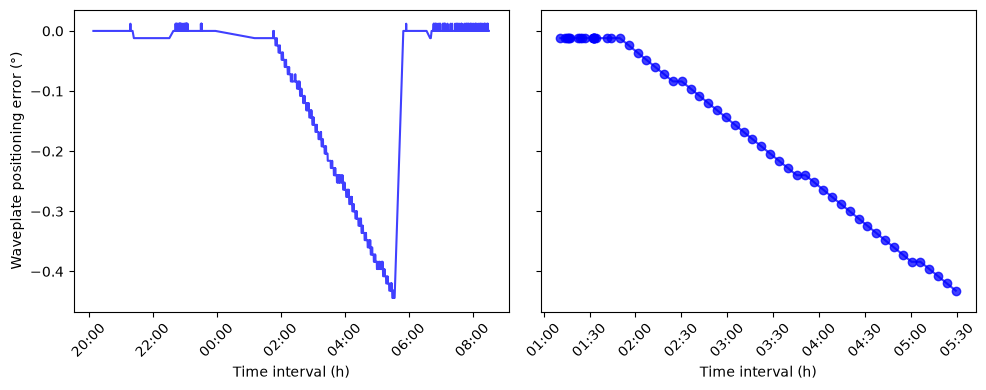

In [ ]:
# ERROR TIME SERIES 20260702

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

night = "20260702"
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["DATE-OBS"], df["ERROR"], "-b", alpha=0.75)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)

df = df[df["SEQINDEX"] == 1]
df = df[df["DATE-OBS"] > datetime(2026, 7, 3, 1)]
df = df[df["DATE-OBS"] < datetime(2026, 7, 3, 5, 30)]
ax = axs[1]
ax.plot(df["DATE-OBS"], df["ERROR"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# ERROR TIME SERIES 20260714

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

night = "20260714"
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.5)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)

df = df[df["SEQINDEX"] == 16]
df = df[df["DATE-OBS"] > datetime(2026, 7, 15, 1)]
df = df[df["DATE-OBS"] < datetime(2026, 7, 15, 4)]
ax = axs[1]
ax.plot(df["DATE-OBS"], df["ERROR"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

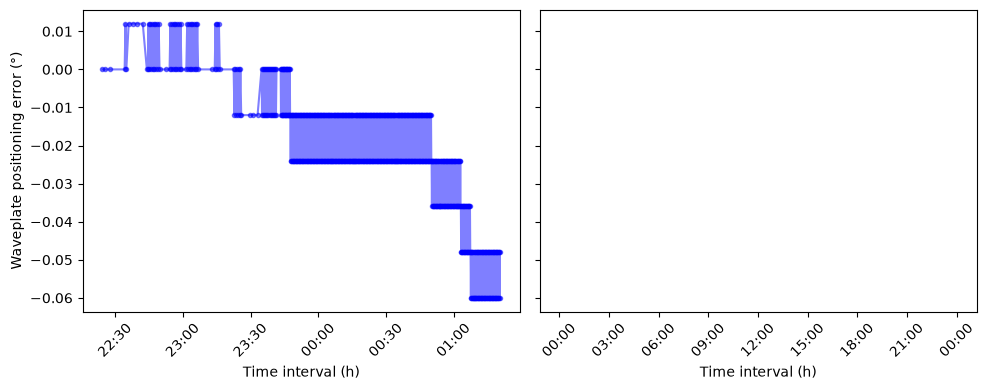

In [64]:
# ERROR TIME SERIES 20260809

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

night = "20260809"
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.5)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)

df = df[df["SEQINDEX"] == 1]
df = df[df["DATE-OBS"] > datetime(2026, 8, 9, 23, 30)]
df = df[df["DATE-OBS"] < datetime(2026, 8, 9, 1, 30)]
ax = axs[1]
ax.plot(df["DATE-OBS"], df["ERROR"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path


night = "20261114"
csv_file = Path.cwd() / "_csv" / f"{night}.csv"
df = pd.read_csv(csv_file)
plt.hist(df["error"], color="blue", edgecolor="black", alpha=0.75)
plt.xlabel("Waveplate positioning error (°)")
plt.ylabel("Frequency")

image_path = Path.cwd() / "_figs" / f"{night}_wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_error_histograms.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()